# LEDGAR — LoRA adapters on DistilBERT (milestone m4)

> **Summary**
> - Our LoRA layer behaves as the method states (exactly the pretrained layer at step 0, $B$ learns first, an exact
>   merge) and, inside DistilBERT, trains the same 814 948 parameters as `peft`: 1.2 % of the model, 82 % of which
>   is the new classification head.
> - Learning rate chosen on validation: 1e-3, the largest tried. At 3 epochs a larger rank (16) adds nothing, while
>   LoRA on every linear layer (1.3 M parameters) matches full fine-tuning (0.790 against 0.791 macro-F1).
> - At 10 epochs full fine-tuning keeps a 1.3-point lead on validation (0.820 against 0.807). LoRA needs four times
>   less memory for weights, gradients and optimizer states, but is not faster on an A100, and it over-fits less.
> - Whether full fine-tuning is worth it is decided on the test set by the paired tests of `06_evaluation.ipynb`.

LoRA keeps the 66 M pretrained weights frozen and trains, next to some projections, a correction of low
rank $r$: $h = Wx + \frac{\alpha}{r} BAx$. Sections 1 and 2 check our implementation on one layer and inside
DistilBERT, against the `peft` library used for the runs; sections 3 and 4 read the runs trained on Colab
(validation only; test scores are in `06_evaluation.ipynb`).

## Setup

In [1]:
import copy
import json
import warnings

warnings.filterwarnings("ignore", message="IProgress not found")

import datasets
import matplotlib.pyplot as plt
import pandas as pd
import torch
import transformers
from torch import nn

from ledgar import runs, train_bert
from ledgar.config import Config, set_seed
from ledgar.models.lora import LoRALinear, inject_lora, make_peft_model, merge_lora

transformers.logging.set_verbosity_error()
transformers.utils.logging.disable_progress_bar()
datasets.disable_progress_bars()
pd.set_option("display.width", 140)

cfg = Config.from_env()
set_seed(cfg.seed)
RESULTS, FIGURES = cfg.path("results"), cfg.path(cfg.reports_dir, "figures")
print(cfg)
print(f"LoRA r = {cfg.lora_r}, alpha = {cfg.lora_alpha}, on {cfg.lora_targets}, learning rate {cfg.lr_lora}")

fast_run=False | seed=0 | device=mps | precision=fp32 | batch_size=8 | grad_accum=4 | model_name=distilbert-base-uncased | max_length=512 | max_words=476 | epochs=10
LoRA r = 8, alpha = 16, on ('q_lin', 'v_lin'), learning rate 0.001


## 1. Does our LoRA layer behave as the method says?

On one 768 × 768 projection: $A$ is random and $B$ starts at zero, so at step 0 the layer must return exactly
what the frozen layer returns, the first gradient must reach $B$ only, and merging $W + \frac{\alpha}{r}BA$
into a plain linear layer must give the same outputs.

In [2]:
torch.manual_seed(cfg.seed)
base = nn.Linear(768, 768)
layer = LoRALinear(base, r=cfg.lora_r, alpha=cfg.lora_alpha)
x = torch.randn(4, 768)
same_at_start = torch.allclose(layer(x), base(x))
layer(x).sum().backward()
n_lora = sum(p.numel() for p in layer.parameters() if p.requires_grad)
assert same_at_start and n_lora == cfg.lora_r * (768 + 768)
assert layer.B.grad.abs().sum() > 0 and layer.A.grad.abs().sum() == 0 and base.weight.grad is None
with torch.no_grad():
    layer.B.normal_()
assert torch.allclose(merge_lora(layer)(x), layer(x), atol=1e-4)
print(
    f"{n_lora:,} trained numbers instead of {768 * 768:,} ({100 * n_lora / (768 * 768):.1f} %), "
    f"scaling alpha / r = {layer.scaling}"
)

12,288 trained numbers instead of 589,824 (2.1 %), scaling alpha / r = 2.0


→ **Consequence:** on a 768 × 768 projection, rank 8 trains 12 288 numbers instead of 589 824 (2.1 %); the layer starts as
the frozen one, so training starts from the pretrained model, not from noise, and the merged layer costs nothing at
inference.

## 2. Inside DistilBERT: what is trained, and does training start from the pretrained model?

`inject_lora` freezes the model, wraps the query and value projections of the 6 blocks, and leaves the new
classification head fully trainable (it has no pretrained values to keep). The logits must be unchanged at
step 0, and `peft`, which the training runs use, must train exactly the same number of parameters.

In [3]:
set_seed(cfg.seed)
model = transformers.AutoModelForSequenceClassification.from_pretrained(
    cfg.model_name, num_labels=cfg.n_classes
)
probe = torch.tensor([[101, 1996, 18712, 2283, 4618, 25209, 1996, 2283, 1012, 102]])
model.eval()
with torch.no_grad():
    before = model(input_ids=probe).logits
reference = copy.deepcopy(model)
inject_lora(model, cfg.lora_targets, cfg.lora_r, cfg.lora_alpha)
with torch.no_grad():
    after = model(input_ids=probe).logits
trainable, total = train_bert.count_parameters(model)
peft_model = make_peft_model(reference, cfg.lora_r, cfg.lora_alpha, cfg.lora_targets)
peft_trainable, _ = train_bert.count_parameters(peft_model)
head = 768 * 768 + 768 + 768 * cfg.n_classes + cfg.n_classes
assert sum(isinstance(m, LoRALinear) for m in model.modules()) == 12 and torch.allclose(
    before, after, atol=1e-5
)
assert trainable == 6 * 2 * cfg.lora_r * (768 + 768) + head == peft_trainable
memory = pd.DataFrame(
    {
        "trainable": [67_030_372, trainable],
        "memory_GB": [
            train_bert.training_memory_gb(0, 67_030_372),
            train_bert.training_memory_gb(total - trainable, trainable),
        ],
    },
    index=["full fine-tuning", f"LoRA r={cfg.lora_r} on q, v"],
)
share = 100 * trainable / total
print(f"adapters {trainable - head:,} + head {head:,} = {trainable:,} trainable ({share:.2f} %)")
print(f"peft trains {peft_trainable:,}")
memory.round(3)

adapters 147,456 + head 667,492 = 814,948 trainable (1.21 %)
peft trains 814,948


,trainable,memory_GB
full fine-tuning,67030372,1.072
"LoRA r=8 on q, v",814948,0.278


→ **Consequence:** the adapters themselves are small (147 456 numbers on 12 projections); most of what LoRA trains is the new
head (667 492), which has no pretrained value to keep. Memory for weights, gradients and Adam drops from 1.07 GB
to 0.28 GB, because a frozen weight needs no gradient and no optimizer state. On a 16 GB laptop or a small GPU,
that is the difference between fitting and not fitting; activations, the same for both, come on top.

## 3. Learning rate, rank and target layers: the trade-off table (validation, seed 0)

Three learning rates for rank 8 on the query and value projections; at the best one, rank 16 (with
$\alpha = 2r$, so the effective step is unchanged) and rank 8 on every linear layer of the blocks, all for 3
epochs; then the chosen LoRA and full fine-tuning trained for 10 epochs (the follow-up of
`04_finetune_distilbert.ipynb`). Full fine-tuning is the reference row. Memory is the estimate for weights, gradients
and Adam states; activations come on top and are the same for all rows.

In [4]:
candidates = {
    "full fine-tuning, lr 5e-5": "bert_lr5e-5_seed0",
    "full fine-tuning, lr 5e-5, 10 epochs": "bert_lr5e-5_ep10_seed0",
    "LoRA r=8 q/v, lr 3e-4": "lora_lr3e-4_seed0",
    "LoRA r=8 q/v, lr 5e-4": "lora_lr5e-4_seed0",
    "LoRA r=8 q/v, lr 1e-3": "lora_lr1e-3_seed0",
    "LoRA r=16 q/v, lr 1e-3": "lora_r16_seed0",
    "LoRA r=8 all linear, lr 1e-3": "lora_all_seed0",
    "LoRA r=8 q/v, lr 1e-3, 10 epochs": "lora_lr1e-3_ep10_seed0",
}
rows = []
for label, name in candidates.items():
    run_dir = RESULTS / name if (RESULTS / name).exists() else RESULTS / "search" / name
    if not run_dir.exists():
        continue
    run = runs.load_run(run_dir)
    m = run["metrics"]
    rows.append(
        {
            "configuration": label,
            "epochs": run["config"]["epochs"],
            "trainable": m["trainable_params"],
            "memory_GB": m["memory_gb_estimate"],
            "minutes": run["manifest"]["duration_s"] / 60,
            "val_macro_f1": m["val"]["macro_f1"],
            "val_accuracy": m["val"]["accuracy"],
            "run": run_dir.name,
        }
    )
tradeoff = pd.DataFrame(rows).set_index("configuration")
tradeoff.round(4)

,epochs,trainable,memory_GB,minutes,val_macro_f1,val_accuracy,run
configuration,,,,,,,
"full fine-tuning, lr 5e-5",3,67030372,1.0725,3.5750,0.7909,0.8652,bert_lr5e-5_seed0
"full fine-tuning, lr 5e-5, 10 epochs",10,67030372,1.0725,11.5217,0.8202,0.8769,bert_lr5e-5_ep10_seed0
"LoRA r=8 q/v, lr 3e-4",3,814948,0.2812,3.6400,0.7586,0.8413,lora_lr3e-4_seed0
"LoRA r=8 q/v, lr 5e-4",3,814948,0.2812,3.6583,0.7767,0.8509,lora_lr5e-4_seed0
"LoRA r=8 q/v, lr 1e-3",3,814948,0.2812,3.6983,0.7849,0.8569,lora_lr1e-3_seed0
"LoRA r=16 q/v, lr 1e-3",3,962404,0.2835,3.5950,0.7848,0.8589,lora_r16_seed0
"LoRA r=8 all linear, lr 1e-3",3,1331044,0.2894,5.5550,0.7905,0.8602,lora_all_seed0
"LoRA r=8 q/v, lr 1e-3, 10 epochs",10,814948,0.2812,11.9383,0.8070,0.8708,lora_lr1e-3_ep10_seed0


→ **Consequence:** the rank is not the bottleneck: going from 8 to 16 adds 147 k parameters and no score (0.7848 against
0.7849). Adapting every linear layer of the blocks instead of query and value does help: at 3 epochs it matches
full fine-tuning (0.7905 against 0.7909) with 2 % of its trainable parameters, at 1.5 times the training time.
Training longer helps LoRA as it helps full fine-tuning (0.785 → 0.807 at 10 epochs), but less: the gap with full
fine-tuning widens from 0.1 to 1.3 points. On an A100 the two take the same time (about 12 minutes for 10
epochs): the backward pass still runs through every frozen layer, so the saving is memory, not speed.

## 4. Do the two methods learn the same way? (10 epochs, seed 0)

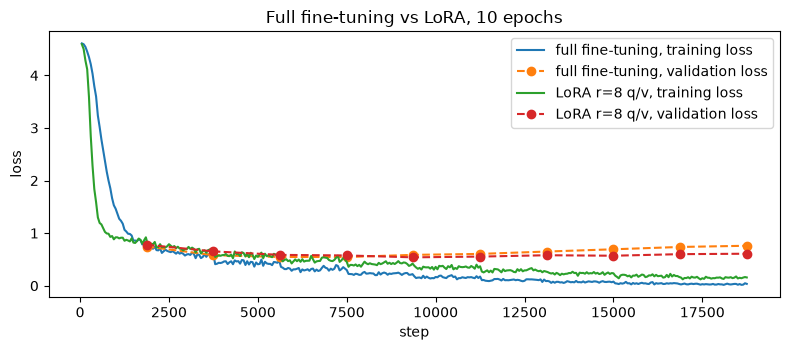

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.6))
for label, name in [
    ("full fine-tuning", "bert_lr5e-5_ep10_seed0"),
    ("LoRA r=8 q/v", "lora_lr1e-3_ep10_seed0"),
]:
    history = json.loads((RESULTS / name / "log_history.json").read_text())
    train = [h for h in history if "loss" in h]
    evals = [h for h in history if "eval_macro_f1" in h]
    ax.plot([h["step"] for h in train], [h["loss"] for h in train], label=f"{label}, training loss")
    ax.plot(
        [h["step"] for h in evals], [h["eval_loss"] for h in evals], "o--", label=f"{label}, validation loss"
    )
ax.set(xlabel="step", ylabel="loss", title="Full fine-tuning vs LoRA, 10 epochs")
ax.legend()
fig.tight_layout()
if not cfg.fast_run:
    fig.savefig(FIGURES / "full_vs_lora_loss.png", dpi=150)

→ **Consequence:** LoRA's loss falls faster at the start (its learning rate is 20 times larger), then both settle. Full
fine-tuning ends up fitting the training clauses almost perfectly (training loss near 0.03) while its validation
loss climbs from epoch 4: it memorises and grows over-confident. LoRA, with far fewer free parameters, keeps a
training loss around 0.15 and a flatter validation loss: it over-fits less, at the price of fewer correct decisions
on validation. The all-linear variant was only trained for 3 epochs; at 10 epochs it might close part of the
gap, which this budget did not test.

## Files used

`results/lora_*` and `results/search/lora_*` (runs; each LoRA run folder holds its adapter, a few MB),
`results/bert_lr5e-5_seed0` and `results/bert_lr5e-5_ep10_seed0` (reference),
`reports/figures/full_vs_lora_loss.png`.